In [1]:
import pickle as pck
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import pandas as pd
import sys
import os

# from functions_PDF import pdf_creator3x3, pdf_creator3x3_indexs, pdf_creator3x3_verticals
# from functions_CONNIE import DataFrame_muons, pixel_rot

## ===== Así se importan las funciones de arhcivos en otras direcciones === ###
module_path = os.path.abspath('../functions') # Adjust relative path as needed
# # Or use an absolute path: module_path = '/home/your_user/projects/utils'

if module_path not in sys.path:
    sys.path.append(module_path)

from functionsNEW import *
# from MCM_Analysis.functions import *


import skimage as sk
import scipy.ndimage as nd
import numpy.ma as ma

# from ROOT import TFile, TTree

## Configuración del estilo de las imágenes
plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth":2,
    "lines.linewidth" : 1,
    "font.size":    15.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',
})

colorbar='jet'
Norm = matplotlib.colors.LogNorm(vmin=10**-1, vmax=10 * 10**0)


In [2]:
######## Nueva definición de la elipcidad ############
# path = './Diccionarios_Espetro_Muones/dict_muons_NSAMP324_Extensions_1_2_4_NIMGS_393_SOL_0.65_ELIP_0.65_NSIGMAS_13_dEDL_0_SIZE_250x539_KeV_.pkl'
# path = './Diccionarios_Espetro_Muones/dict_muons_NSAMP324_Extensions_1_2_4_NIMGS_393_SOL_0.65_ELIP_0.65_NSIGMAS_13_DEDL_0_SIZE_250x539_KeV_n.pkl'
# path = './Diccionarios_Espetro_Muones/dict_muons_NSAMP324_Extensions_1_2_4_NIMGS_393_SOL_0.65_ELIP_0.65_NSIGMAS_13_DEDL_1100_SIZE_250x539_KeV_n.pkl'
# path = './dict_muons_NSAMP400_CONNIE_RUNID_116_Images_684_img1_Sol_0.65_Elip_0.65_SIZE_1022x420__electrons_new.pkl'

# path = './RUN213corr/dict_muons_NSAMP_500_NIMGS_1_SIZE_420x490_NSIGMAS_10_electrons.pkl'
path = "./RUN213corr/dict_muons_RUNID_213_NSAMP500_NIMGS_1_SIZE_420x490_NSIGMAS_10_electrons.pkl"



histogram = open(path, 'rb')
data_histogram = pck.load(histogram)
histogram.close()

Ext = 2
#### Visualizar las keys del diccionario ####
print('Las unidades de los datos están en: ', data_histogram['Energy_Units'])
print('Llaves principales del diccionario: ', data_histogram.keys())
print('Llaves secuandarias por extensión: ', data_histogram[f'extension_{Ext}'].keys(), end='\n')
print('Llaves subsecundarias por extensión: ', data_histogram[f'extension_{Ext}']['muons'].keys(), end='\n\n')

n_muons = data_histogram['All_clusters_detected']
print('Se detectaron ', n_muons, ' muones. ')
DF_muons, list_datamask = DataFrame_muons_v1(data_histogram, extension=Ext)

Las unidades de los datos están en:  1
Llaves principales del diccionario:  dict_keys(['Energy_Units', 'Num_Images', 'extension_1', 'extension_2', 'extension_3', 'extension_5', 'extension_6', 'extension_8', 'extension_10', 'extension_12', 'extension_16', 'All_clusters_detected'])
Llaves secuandarias por extensión:  dict_keys(['muons'])
Llaves subsecundarias por extensión:  dict_keys(['l', 'dedl', 'charge_muons', 'mean_charge', 'median_charge', 'elip', 'sol', 'image', 'label', 'theta', 'phi'])

Se detectaron  3275  muones. 


,Theta (Deg),Phi (Deg),Solidity,Elipticity,Charge (KeV),l (cm),dEdL (KeV/cm)
Muon ID,,,,,,,
3,41.820141,244.012695,0.829181,0.816969,49906.007812,0.090575,550993.125


Shape (Y, X):  (36, 21)


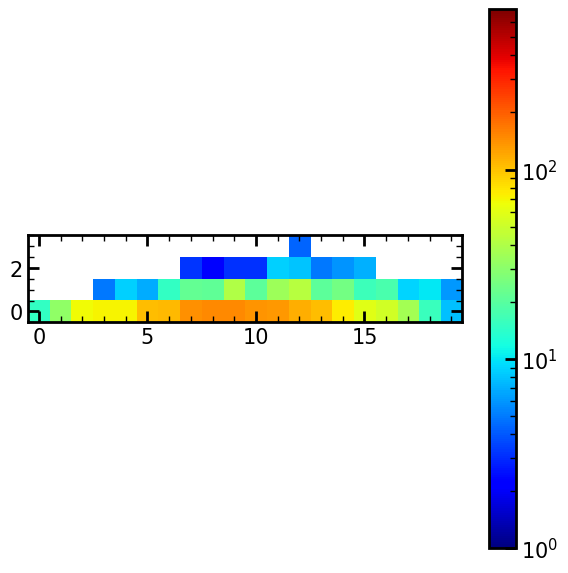

In [3]:
import matplotlib.colors
Norm = matplotlib.colors.LogNorm(vmin=10**0, vmax=7 * 10**2)

n_label = 4

fig, axs = plt.subplots(ncols=1, nrows=1, figsize=[7,7])
x1 = axs.imshow(list_datamask[n_label], cmap=colorbar, norm=Norm)
fig.colorbar(x1, ax=axs)

display(DF_muons.iloc[[n_label-1]])
print('Shape (Y, X): ', list_datamask[n_label-1].shape)
plt.show()

Number of muons in the range: 4 


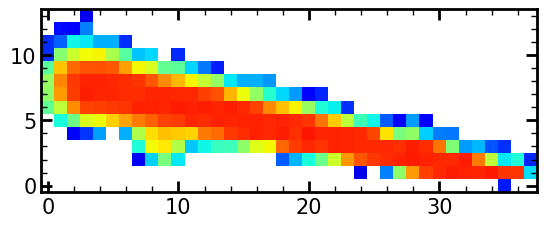

In [8]:
### Se crea el dataframe y se selecciona un rango de datos ###
Ext = 1
DF_muons, list_datamask = DataFrame_muons_v1(data_histogram, extension=Ext)

list_newmatrix = []
list_indexs =[]
range_in_phi = DF_muons[DF_muons['Phi (Deg)'].between(0, 185)]

# range_in_phi = DF_muons[DF_muons['Phi (Deg)'].between(165, 195)]
# range_in_phi = DF_muons[DF_muons['Phi (Deg)'].between(175, 185)]


for index in range_in_phi.index:
    # print(index)
    list_newmatrix.append(list_datamask[index])
    list_indexs.append(index)

print(f'Number of muons in the range: {len(list_newmatrix)} ')

plt.imshow(list_newmatrix[0], norm=Norm, cmap=colorbar)
plt.show()

In [9]:
list_phi_ext1 = data_histogram['extension_1']['phi']
list_mask_rot = []

list_listsnxny = []

for index in list_indexs[:]:
    datamask = list_datamask[index]
    ylen, xlen = datamask.shape
    list_nxny = []

    data_mask_zeros = np.empty((ylen + 150, xlen+50))
    data_mask_zeros[:] = 0
    ylen_zeros, xlen_zeros = data_mask_zeros.shape
    # print(data_mask_zeros.shape)
    
    ### Angle rot ##
    phi_rot = np.pi/2 - list_phi_ext1[index]
    # print(phi_rot, phi_rot + list_phi_ext1[index])

    # print('shape original: ', xlen, ylen)
    # print('shape zeros: ', xlen_zeros, ylen_zeros)

    for y_bin in range(0, ylen):
        for x_bin in range(0, xlen):
            if datamask[y_bin][x_bin] != 0:
                nx, ny = pixel_rot(x_bin=x_bin, x0=0, y_bin=y_bin, y0=0, theta= phi_rot)
                list_nxny.append((nx + 10, ny))
                # print(nx, ny)
                data_mask_zeros[ny][nx+10] = datamask[y_bin][x_bin]

    list_listsnxny.append(list_nxny)
    label_img, nlabels_img = sk.measure.label(data_mask_zeros > 0, connectivity=2, return_num=True)
    loc = nd.find_objects(label_img == 1)[0]
    mask_rot = np.invert(label_img==1)
    data_mask_rot = ma.masked_array(data_mask_zeros, mask_rot)
    # data_mask_rot = ma.masked_array(data_mask_zeros[loc[0].start:loc[0].stop, loc[1].start:loc[1].stop], mask_rot[loc[0].start:loc[0].stop, loc[1].start:loc[1].stop])

    list_mask_rot.append(data_mask_rot)
    # print('Shape rot: ', data_mask_rot.shape[1], data_mask_rot.shape[0])
    
    # plt.imshow(data_mask_rot)
    # plt.show()
#     

In [10]:
# display(list_listsnxny[1]
dict_reps = {}
for duple in list_listsnxny[1]:
    dict_reps[duple] = dict_reps.get(duple, 0) + 1

# display(dict_reps)
n_valuesrep = 0
for value in dict_reps:
    if dict_reps[value]>1:
        n_valuesrep += 1
        print(value, ': ', dict_reps[value])

print('Elements with more reps: ', n_valuesrep)

(10, -3) :  2
Elements with more reps:  1


In [11]:
PDF_rot_name = 'Muons_PHI_BETWEEN_175-185_EXT_DEDL_1300.pdf'
# pdf_creator3x3_verticals(pdf_name=PDF_rot_name, list_pixelmatrix=list_mask_rot)
pdf_creator3x3_verticals(pdf_name=PDF_rot_name, list_pixelmatrix=list_newmatrix)

The PDF is being created
209  muons will be display
Done


0

# Creación de PDF para todos los muones de una extensión

In [ ]:
n_label = 100

fig, axs = plt.subplots(ncols=3, nrows=3, figsize=[7,7])
axs[0,0].imshow(list_datamask[n_label], cmap=colorbar)
axs[0,0].set_title('ID: ' + str(n_label))

axs[0,1].imshow(list_datamask[n_label+1], cmap=colorbar)
axs[0,1].set_title('ID: ' + str(n_label+1))

axs[0,2].imshow(list_datamask[n_label+2], cmap=colorbar)
axs[0,2].set_title('ID: ' + str(n_label+2))

axs[1,0].imshow(list_datamask[n_label+3], cmap=colorbar)
axs[1,0].set_title('ID: ' + str(n_label+3))

axs[1,1].imshow(list_datamask[n_label+4], cmap=colorbar)
axs[1,1].set_title('ID: ' + str(n_label+4))

axs[1,2].imshow(list_datamask[n_label+5], cmap=colorbar)
axs[1,2].set_title('ID: ' + str(n_label+5))

axs[2,0].imshow(list_datamask[n_label+6], cmap=colorbar)
axs[2,0].set_title('ID: ' + str(n_label+6))

axs[2,1].imshow(list_datamask[n_label], cmap=colorbar)
axs[2,1].set_title('ID: ' + str(n_label+7))

axs[2,2].imshow(list_datamask[n_label+8], cmap=colorbar)
axs[2,2].set_title('ID: ' + str(n_label+8))

plt.tight_layout()
plt.show()

In [ ]:
Ext = 1  # Only change this value and the PDF_name

DF_muons, list_datamask = DataFrame_muons(data_histogram, extension=Ext)

# list_datamask = list_datamask[:50]
print('Len: ', len(list_datamask))
### Creación del PDF con el nombre ##
PDF_name = 'Prueba1.pdf'
c = canvas.Canvas(PDF_name, letter)
w, h = A4 ## dimensiones del formato

### Imagen provicional ###
path_image = 'Perfil_Muon.jpg'
color_matrix = [0.4, 0.4470, 0.2410]
coord3x3 = [[0,0],[0,1], [0,2], [1,0], [1,1], [1,2], [2,0], [2,1], [2,2]]
n_last_events = 0

# for extension in (1,2,4):
# c.drawString(50, h - 50, 'Extensión ' + str(Ext)) 
n_muonstot = len(list_datamask)
n_last_events = 0
n_events = 0


fig, axs = plt.subplots(ncols= 3, nrows= 3, figsize = [6,6], facecolor = color_matrix) ## Las hojas tendrán 9 muones
num_pages = 0
# c.showPage()

if (n_muonstot%9) == 0:
    # print('Hola')
    for index in range(0, len(list_datamask)):
        n_muonstot = n_muonstot - 1
        n_events = n_events + 1
        if n_events < 10: 
            # print('n_events: ', n_events)
            axs[coord3x3[n_events - 1][0],coord3x3[n_events - 1][1]].imshow(list_datamask[index], cmap = colorbar)
            axs[coord3x3[n_events - 1][0],coord3x3[n_events - 1][1]].set_title('ID: ' + str(index))

            if n_events == 9:
                n_events = 10
        
        if n_events == 10:
            n_events = 0
            num_pages = num_pages + 1
            fig.savefig(path_image)
            img = ImageReader(path_image)

            # Obtener el ancho y alto de la imagen.
            img_w, img_h = img.getSize()

            # h - img_h es el alto de la hoja menos el alto de la imagen.
            c.drawImage(img, w - img_w + 10, h - img_h - 90)
            c.drawString(w/2, 40, str(num_pages))
            c.showPage()
            # plt.imshow(event)
            # plt.show()
            plt.close()
            ! rm Perfil_Muon.jpg

            fig, axs = plt.subplots(ncols= 3, nrows= 3, figsize = [6,6], facecolor = color_matrix)

elif (n_muonstot%9) != 0:
    # print('No Hola')
    Resto = n_muonstot%9

    for index in range(0, len(list_datamask)):
        n_muonstot = n_muonstot - 1
        n_events = n_events + 1

        if n_muonstot >= Resto:
            print('Primera condicion')
            if n_events < 10: 
                # print('n_events: ', n_events)
                axs[coord3x3[n_events - 1][0],coord3x3[n_events - 1][1]].imshow(list_datamask[index], cmap = colorbar)
                axs[coord3x3[n_events - 1][0],coord3x3[n_events - 1][1]].set_title('ID: ' + str(index))

                if n_events == 9:
                    n_events = 10

            if n_events == 10:
                print('Estoy aqui')
                n_events = 0
                num_pages = num_pages + 1
                fig.savefig(path_image)
                img = ImageReader(path_image)

                # Obtener el ancho y alto de la imagen.
                img_w, img_h = img.getSize()
                print('Aqui ', img_w)

                # h - img_h es el alto de la hoja menos el alto de la imagen.
                c.drawImage(img, w - img_w+10, h - img_h-90)
                c.drawString(w/2, 40, str(num_pages))
                c.showPage()
                # plt.imshow(event)
                # plt.show()
                plt.close()
                ! rm Perfil_Muon.jpg

                fig, axs = plt.subplots(ncols= 3, nrows= 3, figsize = [6,6], facecolor = color_matrix)

        elif n_muonstot<Resto:
            print('Segunda condicion')
            n_last_events = n_last_events + 1

            axs[coord3x3[n_last_events - 1][0],coord3x3[n_last_events - 1][1]].imshow(list_datamask[index], cmap=colorbar)
            axs[coord3x3[n_last_events - 1][0],coord3x3[n_last_events - 1][1]].set_title('ID: ' + str(index))

            if n_muonstot == 0:
                # plt.show()
                num_pages = num_pages + 1
                fig.savefig(path_image)
                img = ImageReader(path_image)

                # Obtener el ancho y alto de la imagen.
                img_w, img_h = img.getSize()

                # h - img_h es el alto de la hoja menos el alto de la imagen.
                c.drawImage(img, w - img_w + 50, h - img_h - 60)
                c.drawString(w/2, 40, str(num_pages))
                c.showPage()
                # plt.imshow(event)
                # plt.show()
                plt.close()
                ! rm Perfil_Muon.jpg

                fig, axs = plt.subplots(ncols= 3, nrows= 3, figsize = [10,10], facecolor = color_matrix)
        
plt.close()
c.save()

Len:  1361
No Hola
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Estoy aqui
Aqui  600
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Estoy aqui
Aqui  600
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Estoy aqui
Aqui  600
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Estoy aqui
Aqui  600
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Primera condicion
Estoy aqui
Aqui  600
Primera condicion
Primera condicion
Primera condicion
Primera cond

# Creción de PDFs para un rango de datos

In [5]:
Ext = 1
DF_muons, list_datamask = DataFrame_muons(data_histogram, extension=Ext)

list_newmatrix = []
list_indexs =[]
# range_in_phi = DF_muons[DF_muons['Phi (Deg)'].between(165, 195)]
range_in_phi = DF_muons[DF_muons['Phi (Deg)'].between(85, 90)]

for index in range_in_phi.index:
    # print(index)
    list_newmatrix.append(list_datamask[index])
    list_indexs.append(index)

print('Muones en el rango deseado: ', len(list_indexs))

# plt.imshow(list_newmatrix[0])
# PDF_name = 'Muons_PHI_BETWEEN_0-90_EXT1_DEDL_1300.pdf'
# PDF_name = 'Muons_PHI_BETWEEN_90-180_EXT1_DEDL_1400.pdf'
PDF_name = 'Muons_PHI_BETWEEN_85-95_EXT1_DEDL_1300.pdf'
pdf_creator3x3_indexs(PDF_name, list_newmatrix[:300], list_indexs[:300], norm=Norm)


Muones en el rango deseado:  171
The PDF is being created
171  muons will be display
Done


0